In [2]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [3]:
df=pd.read_csv(r"C:\Users\Pc\Documents\pfa_stage_project\data\processed\model_data\cleaned_data.csv")
df.head()

,Date,KCL,Phosphate,DAP,TSP,Urea,Gas_US,Gas_EUR,Brent
0,1967-01-01,25.5,12.0,68.5,46.5,49.25,0.16,0.456647,1.33
1,1967-02-01,25.5,12.0,68.5,46.5,49.25,0.16,0.456647,1.33
2,1967-03-01,25.5,12.0,68.5,46.5,49.25,0.16,0.456647,1.33
3,1967-04-01,25.5,12.0,68.5,46.5,49.25,0.16,0.456647,1.33
4,1967-05-01,25.5,12.0,68.5,46.5,49.25,0.16,0.456647,1.33


In [4]:
df.shape

(707, 9)

In [5]:
df.isna().sum()

Date         0
KCL          0
Phosphate    0
DAP          0
TSP          0
Urea         0
Gas_US       0
Gas_EUR      0
Brent        0
dtype: int64

In [6]:
df.columns

Index(['Date', 'KCL', 'Phosphate', 'DAP', 'TSP', 'Urea', 'Gas_US', 'Gas_EUR',
       'Brent'],
      dtype='object')

In [7]:
#calculer la correlation entre les variables
corr = df.drop(columns="Date").corr()

print(corr)

                KCL  Phosphate       DAP       TSP      Urea    Gas_US  \
KCL        1.000000   0.813736  0.833201  0.830480  0.871528  0.503871   
Phosphate  0.813736   1.000000  0.771121  0.771353  0.733577  0.372474   
DAP        0.833201   0.771121  1.000000  0.987964  0.929695  0.528714   
TSP        0.830480   0.771353  0.987964  1.000000  0.923293  0.545750   
Urea       0.871528   0.733577  0.929695  0.923293  1.000000  0.537307   
Gas_US     0.503871   0.372474  0.528714  0.545750  0.537307  1.000000   
Gas_EUR    0.846527   0.710765  0.758970  0.748666  0.820583  0.529386   
Brent      0.798863   0.685764  0.834963  0.837116  0.831829  0.627170   

            Gas_EUR     Brent  
KCL        0.846527  0.798863  
Phosphate  0.710765  0.685764  
DAP        0.758970  0.834963  
TSP        0.748666  0.837116  
Urea       0.820583  0.831829  
Gas_US     0.529386  0.627170  
Gas_EUR    1.000000  0.701755  
Brent      0.701755  1.000000  


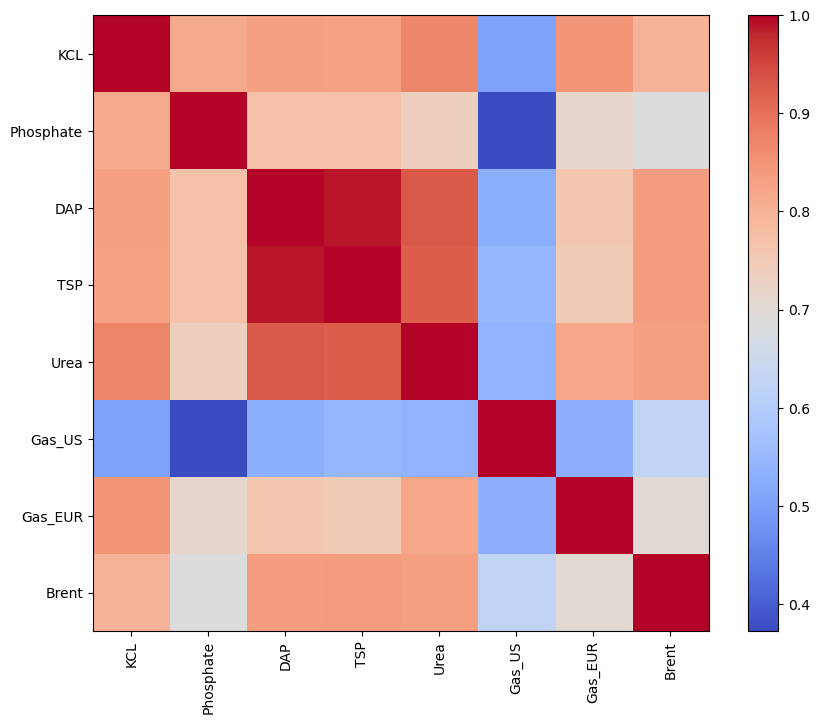

In [8]:
#correlation  entre les variables
corr=df.drop(columns="Date").corr()
plt.figure(figsize=(10,8))
plt.imshow(corr, cmap="coolwarm", interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.show()

In [9]:
#selectionner les variables explicatives
X=df[
    [
        "Phosphate",
         "DAP",
         "TSP",
         "Urea",
         "Gas_US",
         "Gas_EUR",
         "Brent"
    ]
].copy()

In [10]:
def calculate_vif(X):
    vif=pd.DataFrame()
    vif["Variable"]=X.columns
    vif["VIF"]=[
        variance_inflation_factor(X.values,i)
        for i in range(X.shape[1])
    ]
    return vif.sort_values(by="VIF",ascending=False)

In [11]:
#afficher le premier vif
vif = calculate_vif(X)

print(vif)

    Variable         VIF
1        DAP  111.968041
2        TSP  100.810297
3       Urea   27.433135
6      Brent   10.344932
5    Gas_EUR    5.742141
0  Phosphate    5.630685
4     Gas_US    3.921276


In [12]:
#supprimer TSP
X=X.drop(columns=["TSP"])

In [13]:
#recalculer le vif
vif=calculate_vif(X)
print(vif)

    Variable        VIF
2       Urea  27.366854
1        DAP  26.127418
5      Brent  10.266380
4    Gas_EUR   5.739250
0  Phosphate   5.557885
3     Gas_US   3.920838


In [14]:
#supprimer urea
X=X.drop(columns=["Urea"])
#recalculer le vif
vif=calculate_vif(X)
print(vif)

    Variable        VIF
1        DAP  11.785804
4      Brent   9.779685
0  Phosphate   5.487565
3    Gas_EUR   4.555016
2     Gas_US   3.917953


In [15]:
#verifier la signficativité des variables

#variable cible
y=df["KCL"]

#ajouter la constante (intercept)
X_sm=sm.add_constant(X)
#construire le model
model=sm.OLS(y,X_sm).fit()
#afficher le resumé complet
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                    KCL   R-squared:                       0.848
Model:                            OLS   Adj. R-squared:                  0.847
Method:                 Least Squares   F-statistic:                     781.3
Date:                Fri, 31 Jul 2026   Prob (F-statistic):          9.24e-284
Time:                        13:30:28   Log-Likelihood:                -3963.5
No. Observations:                 707   AIC:                             7939.
Df Residuals:                     701   BIC:                             7966.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.6506      4.738      0.137      0.8

In [16]:
X = X.drop(columns=["Gas_US"])

X_sm = sm.add_constant(X)
model = sm.OLS(y, X_sm).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    KCL   R-squared:                       0.847
Model:                            OLS   Adj. R-squared:                  0.847
Method:                 Least Squares   F-statistic:                     974.5
Date:                Fri, 31 Jul 2026   Prob (F-statistic):          8.18e-285
Time:                        13:30:30   Log-Likelihood:                -3964.6
No. Observations:                 707   AIC:                             7939.
Df Residuals:                     702   BIC:                             7962.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.9312      4.405     -0.438      0.6

array([[<Axes: title={'center': 'KCL'}>,
        <Axes: title={'center': 'Phosphate'}>,
        <Axes: title={'center': 'DAP'}>],
       [<Axes: title={'center': 'TSP'}>,
        <Axes: title={'center': 'Urea'}>,
        <Axes: title={'center': 'Gas_US'}>],
       [<Axes: title={'center': 'Gas_EUR'}>,
        <Axes: title={'center': 'Brent'}>, <Axes: >]], dtype=object)

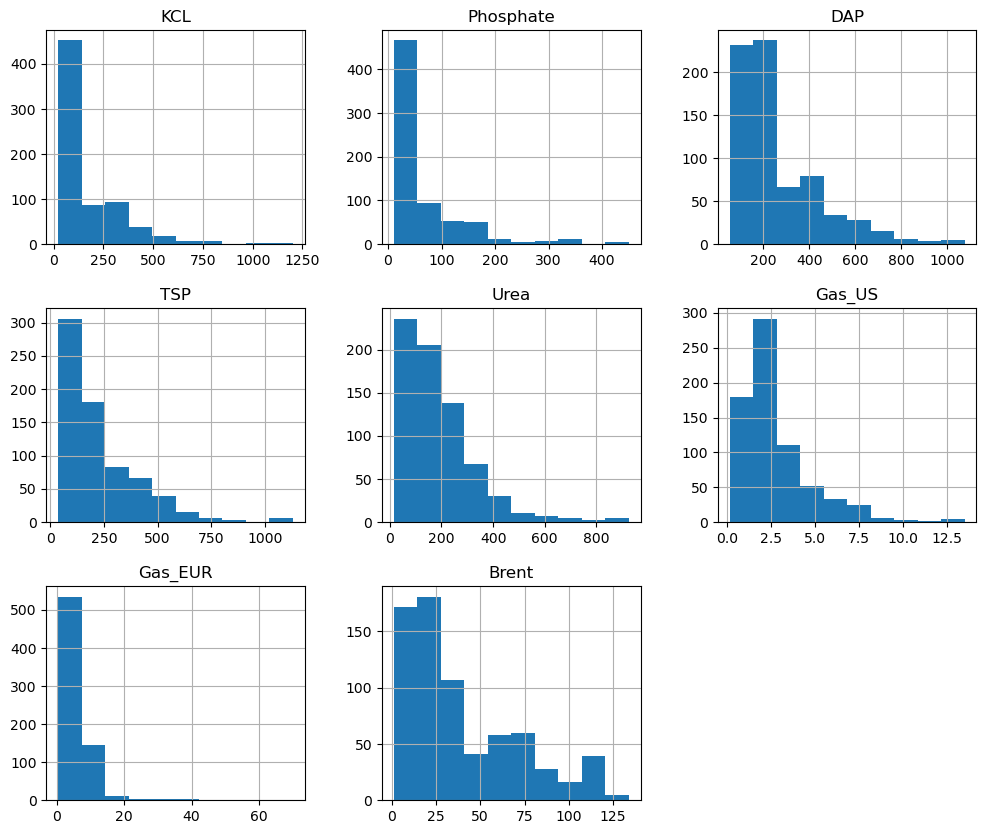

In [17]:
#distribution des variables
df.hist(figsize=(12,10))

In [30]:
df.describe()

,KCL,Phosphate,DAP,TSP,Urea,Gas_US,Gas_EUR,Brent
count,707.000000,707.000000,707.000000,707.000000,707.000000,707.000000,707.000000,707.000000
mean,177.519823,70.528798,260.705205,230.152171,187.864731,2.685030,5.410660,38.641693
std,168.897409,72.629403,184.539741,177.903980,143.505302,2.137044,6.357615,32.213264
min,22.000000,11.000000,54.000000,36.000000,16.000000,0.160000,0.447218,1.210000
25%,75.500000,32.000000,146.000000,124.190000,90.000000,1.490000,2.360000,15.020000
50%,112.500000,44.000000,186.125000,161.000000,141.750000,2.280000,3.650000,27.809999
75%,240.190000,90.000000,357.175000,315.000000,252.500000,3.395000,7.142875,62.322368
max,1202.000000,450.000000,1075.750000,1131.500000,925.000000,13.522619,70.043640,133.873043


{'whiskers': [<matplotlib.lines.Line2D at 0x1ed0d5eefd0>,
 'caps': [<matplotlib.lines.Line2D at 0x1ed0d5ef250>,
 'boxes': [<matplotlib.lines.Line2D at 0x1ed0d5eee90>],
 'medians': [<matplotlib.lines.Line2D at 0x1ed0d5ef4d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1ed0d5ef610>],
 'means': []}

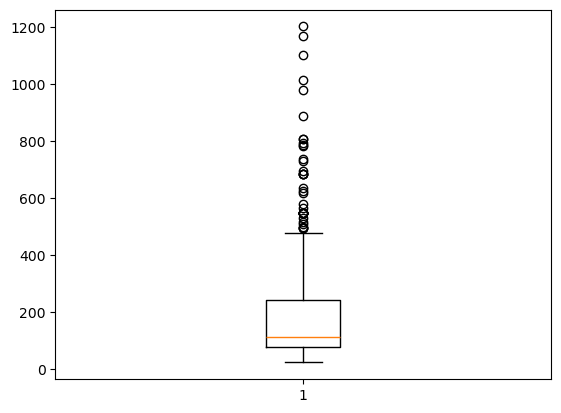

In [32]:
plt.boxplot(df["KCL"])

In [25]:
df_final=df_final = df[
    [
        "Date",
        "KCL",
        "Phosphate",
        "DAP",
        "Gas_EUR",
        "Brent"
    ]
].copy()
df_final.to_csv(r"C:\Users\Pc\Documents\pfa_stage_project\data\processed\model_data\final_dataset.csv",index=False)

In [18]:
df_serie=df[
    [
        "Date",
        "KCL"
    ]
].copy()
df_serie.to_csv(r"C:\Users\Pc\Documents\pfa_stage_project\data\processed\model_data\time_series.csv",index=False)